# 1단계 — 고객을 묶고 특징 설명하기

**질문:** 정답 없이 고객을 묶으면 어떤 차이를 발견할 수 있을까?

같은 입력 6개로 거리 → 표준화 → K-Means → K 선택 → PCA → 군집 요약을 직접 실행한다. 다음 노트북에서 분류와 SHAP을 연결한다. 군집 번호는 정답이나 신용 등급이 아니다.

이 데이터는 가상 고객 10,000명의 합성 데이터다. 원본 열을 추가·수정하지 않는다. 5개 시드의 K 탐색에는 시간이 걸린다. 새 커널에서 위에서부터 실행한다. 그래프 축은 폰트 호환성을 위해 영어로 표시한다.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = None
for candidate in [Path.cwd()] + list(Path.cwd().parents):
    if (candidate / "src" / "analysis_clustering.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("A5-2 또는 notebooks 폴더에서 실행하세요.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import limit_threads
limit_threads(2)
pd.set_option("display.precision", 4)
RANDOM_STATE = 42
feature_columns = ["age", "annual_income", "spending_score", "debt_ratio",
                   "credit_card_count", "overdue_count_6m"]
learning_dir = project_root / "results" / "learning"
figure_dir = learning_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
data_path = project_root / "finance_data.csv"
if not data_path.exists():
    raise FileNotFoundError("finance_data.csv가 없습니다. A5-1과 동일한 제공 데이터를 준비하세요.")
customers = pd.read_csv(data_path)
X = customers[feature_columns].copy()
data_fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert customers.shape == (10000, 8)
assert set(["credit_score", "is_overdue"]).isdisjoint(X.columns)
print("고객 수:", len(customers), "/ 입력 변수 수:", X.shape[1])
print("결측치 수:", X.isna().sum().sum())
display(X.head())

고객 수: 10000 / 입력 변수 수: 6
결측치 수: 0


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0,50,3406.0,54,0.29,1,1
1,25,2161.0,7,0.78,2,0
2,56,6390.0,83,0.88,9,2
3,54,2821.0,10,0.01,2,2
4,50,4925.0,90,0.06,7,1


## 1. 고객 한 쌍의 거리부터 보기

두 고객의 차이를 제곱해 더하면 제곱 유클리드 거리가 된다. 먼저 변수별 기여를 본다. 연 소득은 만원 단위의 수천, 부채 비율은 0~1이므로 원래 숫자를 그대로 쓰면 소득이 거리를 지배한다.

In [2]:
first_customer = X.iloc[0]
second_customer = X.iloc[1]
raw_squared_difference = (first_customer - second_customer) ** 2
raw_distance_share = raw_squared_difference / raw_squared_difference.sum()
display(pd.DataFrame({"customer_0": first_customer, "customer_1": second_customer,
                      "share_of_squared_distance": raw_distance_share}))

,customer_0,customer_1,share_of_squared_distance
age,50.00,25.00,4.0248e-04
annual_income,3406.00,2161.00,9.9817e-01
spending_score,54.00,7.00,1.4225e-03
debt_ratio,0.29,0.78,1.5462e-07
credit_card_count,1.00,2.00,6.4397e-07
overdue_count_6m,1.00,0.00,6.4397e-07


## 2. 단위를 맞추기 — StandardScaler

평균을 빼고 표준편차로 나눠 각 변수의 단위를 맞춘다. `fit`은 기준을 배우고, `transform`은 기준을 적용한다. 여기서는 **현재 고객 집단 전체를 기술하는 군집화**라 전체 입력에 fit한다. 미래 고객에 대한 평가 성능을 측정하는 실험은 아니다. 뒤의 분류는 Train에서만 학습한다.

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X)
Z = scaler.transform(X)
print("표준화 전후 크기:", X.shape, Z.shape)
display(pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=feature_columns))

scaled_squared_difference = (Z[0] - Z[1]) ** 2
scaled_distance_share = scaled_squared_difference / scaled_squared_difference.sum()
display(pd.DataFrame({"raw_share": raw_distance_share,
                      "scaled_share": scaled_distance_share}, index=feature_columns))

표준화 전후 크기: (10000, 6) (10000, 6)


,mean,scale
age,44.6204,14.3428
annual_income,5033.5813,1934.3612
spending_score,49.8742,28.7158
debt_ratio,0.5013,0.2879
credit_card_count,5.0181,2.5714
overdue_count_6m,0.5060,0.7157


,raw_share,scaled_share
age,4.0248e-04,0.2729
annual_income,9.9817e-01,0.0372
spending_score,1.4225e-03,0.2407
debt_ratio,1.5462e-07,0.2602
credit_card_count,6.4397e-07,0.0136
overdue_count_6m,6.4397e-07,0.1754


**확인 질문:** 표준화하면 모든 변수의 의미나 중요도가 같아질까?
<details><summary>답 확인</summary>아니다. 단위를 맞출 뿐이다. 거리 계산에 무엇을 포함할지는 별도의 설계 판단이다. 변수별 역할과 생성 구조를 확인해야 한다.</details>

## 3. K-Means 하나 직접 실행

K는 군집 개수다. 먼저 K=2로 학습하고 고객별 번호와 중심을 본다. 중심은 각 군집 입력의 평균 위치다. 거리와 중심의 반복 계산은 라이브러리가 수행하지만, 학습 입력과 출력은 직접 확인한다.

In [4]:
from sklearn.cluster import KMeans

two_cluster_model = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
two_cluster_model.fit(Z)
print("처음 10명의 군집:", two_cluster_model.labels_[:10])
print("중심의 크기:", two_cluster_model.cluster_centers_.shape)
print("군집 내 제곱거리 합:", two_cluster_model.inertia_)

distance_from_first = np.linalg.norm(two_cluster_model.cluster_centers_ - Z[0], axis=1)
print("첫 고객에서 각 중심까지 거리:", distance_from_first)
assert np.argmin(distance_from_first) == two_cluster_model.labels_[0]

처음 10명의 군집: [0 1 0 0 0 0 1 0 1 0]
중심의 크기: (2, 6)
군집 내 제곱거리 합: 52274.244823389985
첫 고객에서 각 중심까지 거리: [2.01906753 2.40016218]


## 4. K를 바꿔 비교하기

Inertia는 군집 안의 제곱거리 합이며 K가 커지면 보통 작아진다. Elbow는 그 감소가 완만해지는 지점을 보는 방법이다. Silhouette은 같은 군집과의 응집도와 다른 군집과의 분리도를 함께 본다. 높을수록 분리가 뚜렷하지만 진짜 고객 유형을 증명하는 수치는 아니다.

먼저 K 하나를 평가하는 함수를 만든다. 데이터·출력 구조는 앞에서 확인했다. 계산량을 줄이기 위해 Silhouette은 4,000명 표본에서 잰다. 같은 시드의 표본은 K 사이에 동일하다.

In [5]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

def evaluate_one_k(Z_input, cluster_count, seed):
    estimator = KMeans(n_clusters=cluster_count, n_init=10, random_state=seed)
    cluster_labels = estimator.fit_predict(Z_input)
    random_generator = np.random.RandomState(seed)
    sample_indices = random_generator.choice(len(Z_input), min(4000, len(Z_input)), replace=False)
    silhouette = silhouette_score(Z_input[sample_indices], cluster_labels[sample_indices])
    return estimator.inertia_, silhouette, cluster_labels

example_inertia, example_silhouette, example_labels = evaluate_one_k(Z, 2, 0)
print("K=2, seed=0:", example_inertia, example_silhouette)

K=2, seed=0: 52274.244823389985 0.13694395705980023


같은 K라도 시작 중심이 다르면 결과가 달라질 수 있다. 시드 5개로 반복하고, 군집 배정의 일관성을 ARI로 측정한다. ARI는 두 배정의 번호가 달라도 같은 묶음이면 1이다. 아래 리스트에는 K 하나당 요약 딕셔너리 하나를 저장한다.

In [6]:
from itertools import combinations

k_values = range(2, 9)
seeds = range(5)
scan_rows = []
for cluster_count in k_values:
    inertias = []
    silhouettes = []
    label_sets = []
    for seed in seeds:
        inertia, silhouette, cluster_labels = evaluate_one_k(Z, cluster_count, seed)
        inertias.append(inertia)
        silhouettes.append(silhouette)
        label_sets.append(cluster_labels)
    stability_scores = []
    for first_labels, second_labels in combinations(label_sets, 2):
        stability_scores.append(adjusted_rand_score(first_labels, second_labels))
    scan_rows.append({
        "k": cluster_count,
        "inertia": float(np.mean(inertias)),
        "silhouette_mean": float(np.mean(silhouettes)),
        "silhouette_std": float(np.std(silhouettes)),
        "silhouette_se": float(np.std(silhouettes) / np.sqrt(len(silhouettes))),
        "ari_mean": float(np.mean(stability_scores)),
    })
scan_table = pd.DataFrame(scan_rows).set_index("k")
display(scan_table)

,inertia,silhouette_mean,silhouette_std,silhouette_se,ari_mean
k,,,,,
2,52308.5655,0.1348,0.0045,0.0020,0.6000
3,47181.3505,0.1207,0.0014,0.0006,0.4503
4,43175.8442,0.1274,0.0020,0.0009,0.3473
5,39863.0410,0.1317,0.0016,0.0007,0.3842
6,37316.5849,0.1330,0.0014,0.0006,0.6067
7,35288.0576,0.1312,0.0011,0.0005,0.5266
8,33656.2007,0.1297,0.0024,0.0011,0.5995


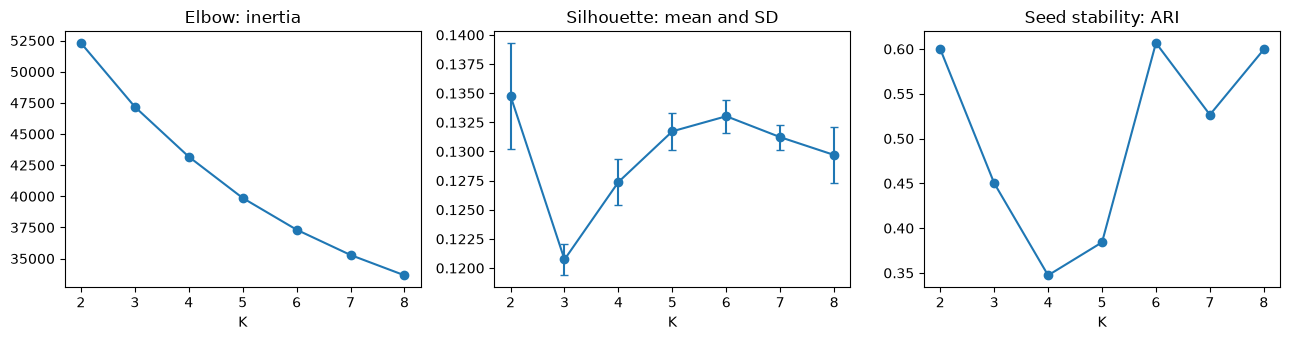

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(scan_table.index, scan_table["inertia"], marker="o")
axes[0].set_title("Elbow: inertia")
axes[1].errorbar(scan_table.index, scan_table["silhouette_mean"],
                 yerr=scan_table["silhouette_std"], marker="o", capsize=3)
axes[1].set_title("Silhouette: mean and SD")
axes[2].plot(scan_table.index, scan_table["ari_mean"], marker="o")
axes[2].set_title("Seed stability: ARI")
for axis in axes:
    axis.set_xlabel("K")
plt.tight_layout()
plt.savefig(figure_dir / "01_k_selection.png", dpi=140)
plt.show()

## 5. 지표와 해석을 연결해 K 선택

이 실험은 Silhouette 최고 평균에서 표준오차 하나를 뺀 기준 이상을 후보로 두고, ARI 0.5 이상인 후보 중 구별 가능한 입력 축이 많은 K를 선택한다. 구별 축은 어느 중심이라도 전체 평균에서 0.5표준편차 이상 벗어난 변수다. 이 기준은 **업무상 해석을 위한 휴리스틱**이며 통계적 동등성 검정이 아니다. Elbow에 뚜렷한 꺾임이 없다면 있다고 꾸미지 않는다. 타깃은 이 선택에 사용하지 않는다.

In [8]:
best_row = scan_table.loc[scan_table["silhouette_mean"].idxmax()]
silhouette_cutoff = best_row["silhouette_mean"] - best_row["silhouette_se"]
within_one_se = scan_table.index[scan_table["silhouette_mean"] >= silhouette_cutoff].tolist()
stable_candidates = []
for cluster_count in within_one_se:
    if scan_table.loc[cluster_count, "ari_mean"] >= 0.5:
        stable_candidates.append(cluster_count)

candidate_rows = []
for cluster_count in stable_candidates:
    candidate_model = KMeans(n_clusters=cluster_count, n_init=10, random_state=RANDOM_STATE)
    candidate_model.fit(Z)
    distinguishes = (np.abs(candidate_model.cluster_centers_) >= 0.5).any(axis=0)
    names = []
    for feature_name, is_distinguishing in zip(feature_columns, distinguishes):
        if is_distinguishing:
            names.append(feature_name)
    candidate_rows.append({"k": cluster_count, "axis_count": len(names), "features": names})

if candidate_rows:
    candidate_table = pd.DataFrame(candidate_rows).sort_values(["axis_count", "k"], ascending=[False, True])
    selected_k = int(candidate_table.iloc[0]["k"])
    display(candidate_table)
else:
    selected_k = int(best_row.name)
print("선택한 K:", selected_k)

,k,axis_count,features
1,6,5,"[age, spending_score, debt_ratio, credit_card_..."
0,2,1,[overdue_count_6m]


선택한 K: 6


**출력 읽기:** K별 점수 차이와 절대 수준을 함께 본다. 이 합성 데이터의 입력은 독립 난수로 생성됐으므로 명확한 자연 군집을 기대하기 어렵다. 고객을 몇 묶음으로 설명할지는 탐색적 결정이다. K를 바꾸면 번호와 페르소나도 달라질 수 있다.

## 6. 최종 군집과 원래 단위의 특징

선택한 K로 학습한 뒤 원래 변수의 평균을 본다. 군집 번호는 이름표다. 학습 후 연체율을 비교할 수 있지만, 그것이 군집 정답이나 모델 성능 평가는 아니다. 결과표는 원본 CSV가 아닌 별도 복사본으로 만든다.

In [9]:
cluster_model = KMeans(n_clusters=selected_k, n_init=10, random_state=RANDOM_STATE)
cluster_labels = cluster_model.fit_predict(Z)
cluster_centers = cluster_model.cluster_centers_
centers_in_original_units = scaler.inverse_transform(cluster_centers)

profile_table = pd.DataFrame(centers_in_original_units, columns=feature_columns)
profile_table.index.name = "cluster"
profile_table["customers"] = np.bincount(cluster_labels, minlength=selected_k)
profile_table["overdue_rate"] = 0.0
for cluster_id in range(selected_k):
    member_mask = cluster_labels == cluster_id
    profile_table.loc[cluster_id, "overdue_rate"] = customers.loc[member_mask, "is_overdue"].mean()
display(profile_table)
assert profile_table["customers"].sum() == len(customers)

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,customers,overdue_rate
cluster,,,,,,,,
0,44.8971,5031.3617,50.7422,0.4888,4.9407,2.1726,962,0.3898
1,34.4818,5206.2144,62.6684,0.7305,3.0688,0.3385,1758,0.1320
2,32.9120,5218.8463,30.1515,0.4921,7.1554,0.3210,1842,0.0765
3,47.0395,5080.7908,77.2284,0.2256,5.4880,0.3200,1922,0.0281
4,50.5196,4816.6051,25.5587,0.3751,2.7975,0.3126,1788,0.0710
5,58.4523,4833.9225,52.1203,0.7222,6.5414,0.3528,1728,0.1574


### 6-1. 페르소나는 평균과 근거에서 붙이기

첫 군집을 먼저 설명한다. 중심의 z값이 +0.5 이상이면 해당 입력이 평균보다 높은 편, -0.5 이하면 낮은 편이라고 요약한다. 예를 들어 연체 횟수 높은 묶음에는 상환 관리 상담 가설을 세울 수 있다. 나이·카드 수가 다르다는 사실만으로 위험 원인이나 거절 사유라고 단정하지 않는다.

In [10]:
center_z_table = pd.DataFrame(cluster_centers, columns=feature_columns)
display(center_z_table)
persona_rows = []
for cluster_id in range(selected_k):
    descriptions = []
    for feature_name in feature_columns:
        z_value = center_z_table.loc[cluster_id, feature_name]
        if z_value >= 0.5:
            descriptions.append(feature_name + " 높은 편")
        elif z_value <= -0.5:
            descriptions.append(feature_name + " 낮은 편")
    if center_z_table.loc[cluster_id, "overdue_count_6m"] >= 0.5:
        action_hypothesis = "상환 일정 점검·상담 대상 가설; 개별 모델 설명 확인"
    elif center_z_table.loc[cluster_id, "debt_ratio"] >= 0.5:
        action_hypothesis = "부채 부담 상담 대상 가설; 개별 모델 설명 확인"
    else:
        action_hypothesis = "고객 수요·선호 조사 후 상품 안내 가설 검토"
    persona_rows.append({"cluster": cluster_id, "description": ", ".join(descriptions),
                         "action_hypothesis": action_hypothesis})
persona_table = pd.DataFrame(persona_rows)
display(persona_table)

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0,0.0193,-0.0011,0.0302,-0.0435,-0.0301,2.3287
1,-0.7069,0.0892,0.4455,0.7959,-0.7581,-0.2341
2,-0.8163,0.0958,-0.6868,-0.0320,0.8312,-0.2585
3,0.1687,0.0244,0.9526,-0.9578,0.1828,-0.2599
4,0.4113,-0.1122,-0.8468,-0.4385,-0.8636,-0.2702
5,0.9644,-0.1032,0.0782,0.7672,0.5924,-0.2141


,cluster,description,action_hypothesis
0,0,overdue_count_6m 높은 편,상환 일정 점검·상담 대상 가설; 개별 모델 설명 확인
1,1,"age 낮은 편, debt_ratio 높은 편, credit_card_count 낮은 편",부채 부담 상담 대상 가설; 개별 모델 설명 확인
2,2,"age 낮은 편, spending_score 낮은 편, credit_card_cou...",고객 수요·선호 조사 후 상품 안내 가설 검토
3,3,"spending_score 높은 편, debt_ratio 낮은 편",고객 수요·선호 조사 후 상품 안내 가설 검토
4,4,"spending_score 낮은 편, credit_card_count 낮은 편",고객 수요·선호 조사 후 상품 안내 가설 검토
5,5,"age 높은 편, debt_ratio 높은 편, credit_card_count 높은 편",부채 부담 상담 대상 가설; 개별 모델 설명 확인


## 7. PCA — 6차원 군집을 2차원에서 보기

PCA의 축은 원래 변수의 가중 합이다. 군집은 원래 6개 표준화 입력에서 만들고, PCA는 그림을 그리는 데만 사용한다. 2차원 설명 분산이 낮으면 그림에 드러나지 않는 차이가 많다는 뜻이다. 그림의 겹침만으로 군집이 틀렸다고 단정하지 않는다.

좌표 크기: (10000, 2)
각 축 설명 분산: [0.17474758 0.17132829]
두 축 합: 0.3460758738196657


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
PC1,0.4256,-0.0752,0.6249,-0.5583,0.2391,0.2319
PC2,-0.5012,0.6914,0.0352,-0.2391,0.4608,-0.0015


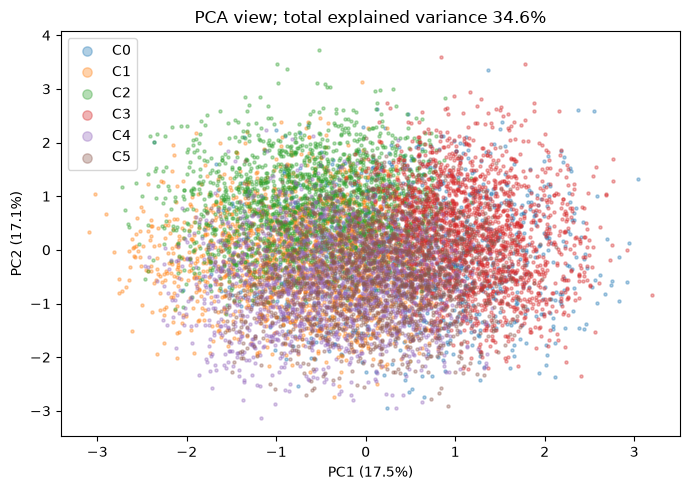

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(Z)
print("좌표 크기:", coordinates.shape)
print("각 축 설명 분산:", pca.explained_variance_ratio_)
print("두 축 합:", pca.explained_variance_ratio_.sum())
display(pd.DataFrame(pca.components_, columns=feature_columns, index=["PC1", "PC2"]))

fig, axis = plt.subplots(figsize=(7, 5))
for cluster_id in range(selected_k):
    member_mask = cluster_labels == cluster_id
    axis.scatter(coordinates[member_mask, 0], coordinates[member_mask, 1],
                 s=5, alpha=0.35, label=f"C{cluster_id}")
axis.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axis.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axis.set_title(f"PCA view; total explained variance {pca.explained_variance_ratio_.sum():.1%}")
axis.legend(markerscale=3)
plt.tight_layout()
plt.savefig(figure_dir / "02_pca_clusters.png", dpi=140)
plt.show()

**확인 질문:** PC1은 소득이고 PC2는 부채 비율일까?
<details><summary>답 확인</summary>아니다. 위 표의 가중치로 여러 변수를 섞은 축이다. 고객 특성은 PCA 좌표 자체보다 원래 변수의 평균과 분포로 설명한다.</details>

## 8. 같은 계산의 모듈 연결과 다음 단계 저장

앞에서 펼친 표준화·K 선택이 기존 함수와 같은 결과인지 확인한다. 최종 군집 번호는 기존 보고서가 연체율 순으로 다시 붙인 번호와 다를 수 있다. ARI는 번호가 달라도 같은 배정인지 확인할 수 있다.

In [12]:
from src import clustering

module_scaler = clustering.fit_scaler(X)
np.testing.assert_allclose(module_scaler.transform(X), Z)
module_selection = clustering.select_k(scan_rows, Z)
assert module_selection["final_k"] == selected_k
module_cluster = clustering.fit_final(Z, customers, selected_k)
assert adjusted_rand_score(module_cluster.labels_, cluster_labels) == 1.0
print("기존 모듈과 표준화·K 선택·군집 배정 일치")

기존 모듈과 표준화·K 선택·군집 배정 일치


In [13]:
np.savez_compressed(
    learning_dir / "clustering.npz",
    labels=cluster_labels, centers=cluster_centers,
    scaler_mean=scaler.mean_, scaler_scale=scaler.scale_,
)
metadata = {"data_sha256": data_fingerprint, "features": feature_columns,
            "selected_k": selected_k, "rows": len(customers), "random_state": RANDOM_STATE}
(learning_dir / "clustering_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
profile_table.to_csv(learning_dir / "cluster_profiles.csv")
persona_table.to_csv(learning_dir / "personas.csv", index=False)
print("다음: analysis_shap.ipynb")

다음: analysis_shap.ipynb


다음 노트북은 이 군집 결과를 읽어 같은 고객의 모델 판단과 연결한다. 고객 입력 6개는 그대로 유지한다. 전체 집단의 군집화와 Train/Test로 나눈 지도학습은 목적과 평가 방식이 다르다.

알고리즘 비교와 대시보드는 확장 주제다. 기존 CLI의 `src.compare`와 `app.py`에서 이어갈 수 있다. 기존 `results/clustering.json`과 최종 보고서 그림은 이 실습으로 덮어쓰지 않는다.